# OPD sign convention in `speckle_opd_retrieval`

**Convention (all methods):** textbook optical path difference

$$\mathrm{OPD}(x, y) = \int \big(n(x, y, z) - n_\text{medium}\big)\,dz ,$$

so an object of **higher RI than the medium** (phase *lag*, it *converges* the field like a positive lens) has
**positive** OPD, and an object of lower RI (phase *lead*, diverging) has **negative** OPD.

| | higher RI than medium | lower RI than medium |
|---|---|---|
| phase | lag | lead |
| field behind the object | converging | diverging |
| speckles move | toward the object centre | away from it |
| **OPD** | **> 0** | **< 0** |

In the package: displacement $d$ [px] with $\text{specimen}(x + d) = \text{reference}(x)$, fields ordered $(y, x)$, and

$$\mathrm{OPD} = \frac{p^2}{z}\int d \qquad (p = \text{pixel size},\ z = \text{mask–sensor distance}),$$

applied once in `core` for every method. There are no sign options. This notebook shows, step by step, why this
formula has a plus sign:
1. BPM through a bead: OPD > 0 for higher RI, and the field converges;
2. why the *phase* sign depends on the time convention, while the OPD does not;
3. speckle simulation + DIC: speckles move toward a converging region, so $+p^2/z\int d$ gives OPD > 0;
4. Deep CWFS: the networks' training labels are $-d$, so the method uses $d = -\text{flow}$;
5. summary for all methods.

In [1]:
import csv, json, os
import numpy as np
import matplotlib.pyplot as plt
from scipy.ndimage import gaussian_filter
from speckle_opd_retrieval import Setup, get_method, load_image

plt.rcParams.update({"figure.dpi": 100, "image.origin": "lower"})
SIGNED, INTENSITY = "RdBu_r", "gray"          # diverging, centred on 0 / sequential for intensities

def show(ax, fig, a, title, label, signed=True, extent=None, cmap=None):
    v = np.percentile(np.abs(a), 99.5) or 1.0
    im = ax.imshow(a, cmap=cmap or (SIGNED if signed else INTENSITY), vmin=-v if signed else 0, vmax=v, extent=extent)
    ax.set_title(title, fontsize=10)
    fig.colorbar(im, ax=ax, label=label, fraction=0.046, pad=0.03)
    return im

## 1. BPM through a bead of higher RI

Split-step beam propagation (wide-angle angular spectrum): a plane wave passes a sphere with $n = 1.38$ in water
($n = 1.33$), radius 3 µm, λ = 530 nm. Fields are written as $u\,e^{i(kz-\omega t)}$ (Goodman, most physics texts and
BPM codes), so propagating a distance $\Delta z$ in RI $n$ multiplies $u$ by $e^{+ik_0 n \Delta z}$: a region of higher
RI adds phase, i.e. the wave lags. The phase of the exit field (back-propagated to the bead centre plane) divided by
$k_0$ is compared with the projected $\int(n - n_\text{m})\,dz$.

projected ∫(n_b - n_m) dz at centre: +0.300 µm
BPM phase/k0 at centre:              +0.297 µm
on-axis focus behind the bead at z = 17.2 µm, I/I0 = 17.7  -> converging


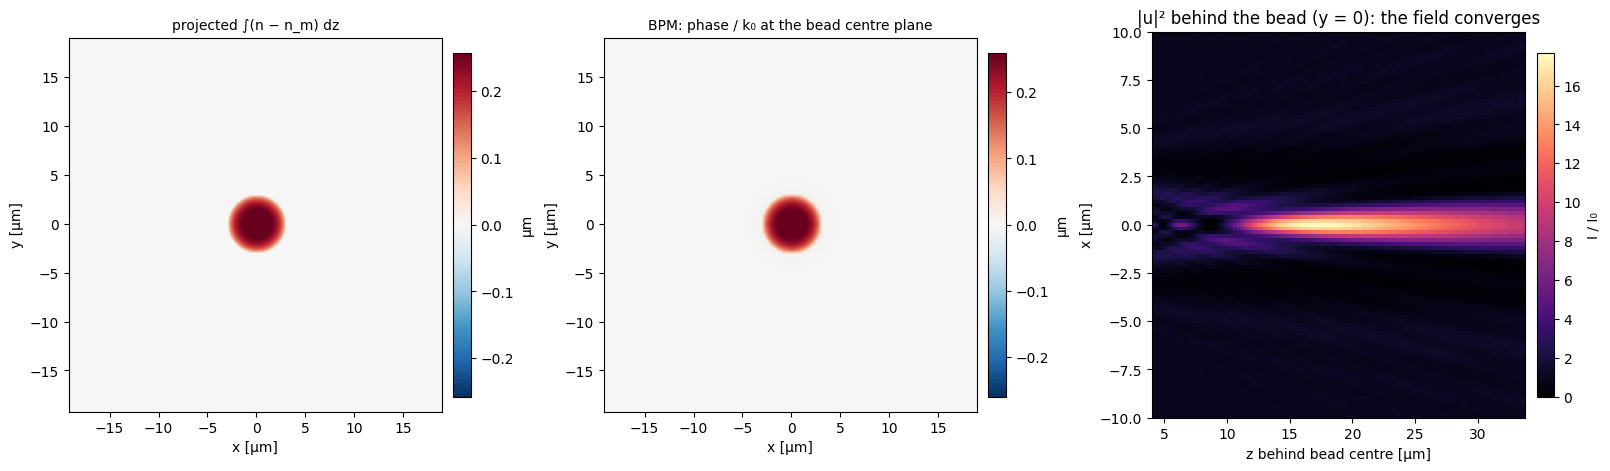

In [2]:
wl, n_m, n_b, R = 0.53, 1.33, 1.38, 3.0                    # µm
N, dx, dz = 192, 0.2, 0.1
k0 = 2 * np.pi / wl
x = (np.arange(N) - N / 2) * dx
X, Y = np.meshgrid(x, x)
f = 2 * np.pi * np.fft.fftfreq(N, dx)
KX, KY = np.meshgrid(f, f)
kz = np.sqrt(np.maximum((k0 * n_m) ** 2 - KX**2 - KY**2, 0))
band = (KX**2 + KY**2) < (0.95 * k0 * n_m) ** 2

def bpm(sign):
    # sign=+1: fields ~ exp(+i(kz - wt)); sign=-1: fields ~ exp(+i(wt - kz))
    H = np.exp(sign * 1j * kz * dz) * band
    u = np.ones((N, N), complex)
    zs = np.arange(-R - 1, R + 1, dz)
    for z in zs:
        dn = np.where(X**2 + Y**2 + z**2 < R**2, n_b - n_m, 0.0)
        u = np.fft.ifft2(np.fft.fft2(u * np.exp(sign * 1j * k0 * dn * dz)) * H)
    centre = np.fft.ifft2(np.fft.fft2(u) * np.exp(-sign * 1j * kz * (R + 1)) * band)
    phase = np.unwrap(np.unwrap(np.angle(centre / centre[5, 5]), axis=0), axis=1)
    zb = np.arange(0.25, 30, 0.25)                           # behind the bead
    xz = np.array([np.abs(np.fft.ifft2(np.fft.fft2(u) * np.exp(sign * 1j * kz * s) * band)[N // 2]) ** 2 for s in zb])
    return phase / k0, xz, zs[-1] + zb

projected = 2 * np.sqrt(np.maximum(R**2 - X**2 - Y**2, 0)) * (n_b - n_m)
opd_bpm, xz, zb = bpm(+1)
c = N // 2
print(f"projected ∫(n_b - n_m) dz at centre: {projected[c, c]:+.3f} µm")
print(f"BPM phase/k0 at centre:              {opd_bpm[c, c]:+.3f} µm")
print(f"on-axis focus behind the bead at z = {zb[np.argmax(xz[:, c])]:.1f} µm, I/I0 = {xz[:, c].max():.1f}  -> converging")

fig, axs = plt.subplots(1, 3, figsize=(16, 4.6), layout="constrained")
ext = [x[0], x[-1], x[0], x[-1]]
show(axs[0], fig, projected, "projected ∫(n − n_m) dz", "µm", extent=ext)
show(axs[1], fig, opd_bpm, "BPM: phase / k₀ at the bead centre plane", "µm", extent=ext)
im = axs[2].pcolormesh(zb, x, xz.T, cmap="magma", vmin=0, shading="auto")
axs[2].set(xlabel="z behind bead centre [µm]", ylabel="x [µm]", ylim=(-10, 10),
           title="|u|² behind the bead (y = 0): the field converges")
fig.colorbar(im, ax=axs[2], label="I / I₀", fraction=0.046, pad=0.03)
for a in axs[:2]:
    a.set(xlabel="x [µm]", ylabel="y [µm]")
plt.show()

**Result:** for a bead of higher RI, OPD = phase/$k_0$ is **positive** and equals $\int(n-n_\text{m})\,dz$; the
bead focuses the light behind it (converging).

## 2. Phase sign vs. OPD sign

The *phase* of a field depends on how the time dependence is written. With $e^{i(\omega t - kz)}$ (common in
engineering), the same bead gives the opposite phase. The OPD — a path length — does not change; only the label on
the phase does. This is where a "higher RI → negative" convention comes from: it is phase/$k_0$ in the
$e^{i(\omega t - kz)}$ convention. The package reports the OPD (path length), so the sign is positive for higher RI.

phase/k0 at centre, exp(+i(kz - wt)): +0.297 µm   <- OPD (package)
phase/k0 at centre, exp(+i(wt - kz)): -0.297 µm   <- same physics, opposite phase label


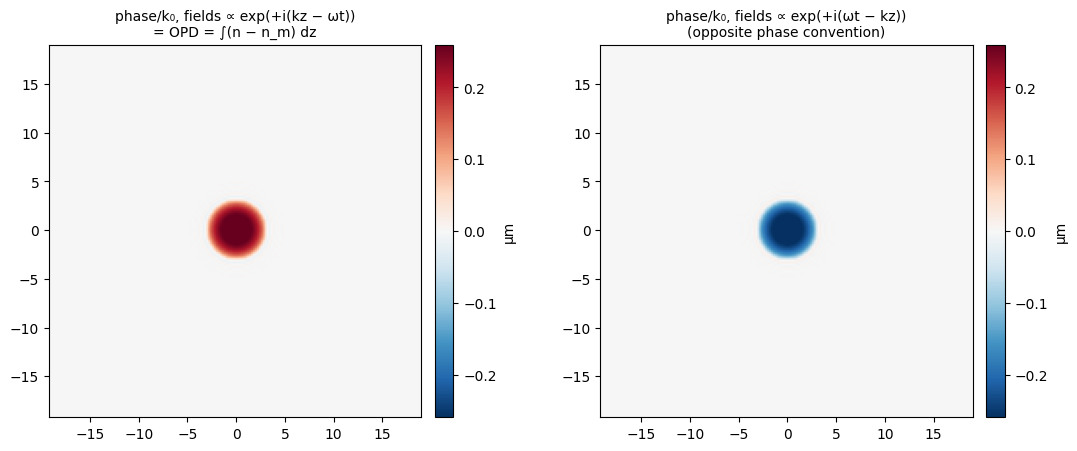

In [3]:
opd_eng, _, _ = bpm(-1)
print(f"phase/k0 at centre, exp(+i(kz - wt)): {opd_bpm[c, c]:+.3f} µm   <- OPD (package)")
print(f"phase/k0 at centre, exp(+i(wt - kz)): {opd_eng[c, c]:+.3f} µm   <- same physics, opposite phase label")
fig, axs = plt.subplots(1, 2, figsize=(11, 4.4), layout="constrained")
show(axs[0], fig, opd_bpm, "phase/k₀, fields ∝ exp(+i(kz − ωt))\n= OPD = ∫(n − n_m) dz", "µm", extent=ext)
show(axs[1], fig, opd_eng, "phase/k₀, fields ∝ exp(+i(ωt − kz))\n(opposite phase convention)", "µm", extent=ext)
plt.show()

## 3. Speckles move toward a converging region → $\mathrm{OPD} = +\frac{p^2}{z}\int d$

Geometrically, a ray leaving a thin object is tilted by $\nabla\mathrm{OPD}$ (it bends toward higher OPD — a
positive lens bends rays toward its thick centre). After the mask–sensor distance $z$ the speckle pattern is shifted
by $z\,\nabla\mathrm{OPD}$. In pixels, with $\text{specimen}(x + d) = \text{reference}(x)$:

$$d = \frac{z}{p^2}\,\nabla_\text{px}\mathrm{OPD} \quad\Longrightarrow\quad \mathrm{OPD} = \frac{p^2}{z}\int d .$$

Check with a wave simulation: a random diffuser with a thin object of higher or lower RI in front of it,
angular-spectrum propagation over $z$ = 1 mm, then the package's DIC. (The same simulation is
`tests/test_opd_sign_convention_physical_speckle_simulation.py`. This diffuser scatters strongly, so DIC recovers
only part of the amplitude; the sign is what matters here.)

higher RI (lag, converging): true OPD centre +0.15 µm, package OPD centre +0.023 µm, corr = +0.83


lower RI (lead, diverging): true OPD centre -0.15 µm, package OPD centre -0.023 µm, corr = +0.84


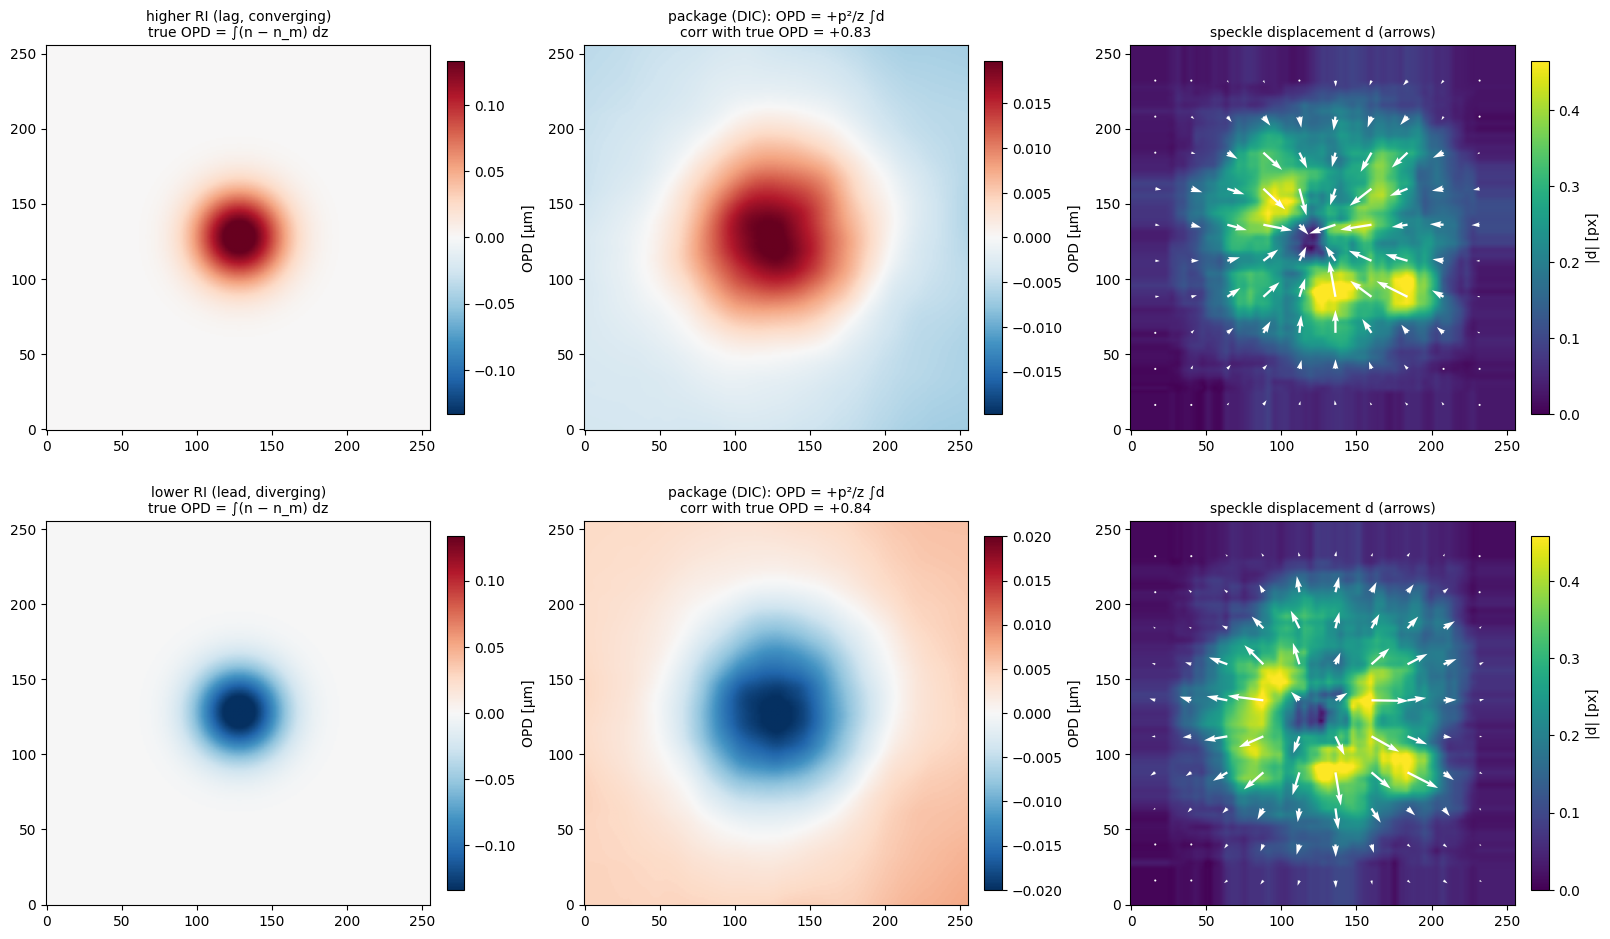

In [4]:
Ns, ps, z_s = 256, 1.0e-6, 1.0e-3
ks = 2 * np.pi / 0.53e-6
diffuser = np.exp(1j * 8 * gaussian_filter(np.random.default_rng(0).standard_normal((Ns, Ns)), 2.0))
fs = 2 * np.pi * np.fft.fftfreq(Ns, ps)
FX, FY = np.meshgrid(fs, fs)
Hs = np.exp(1j * z_s * np.sqrt(np.maximum(ks**2 - FX**2 - FY**2, 0)))
prop = lambda u: np.fft.ifft2(np.fft.fft2(u) * Hs)
ys, xs = (np.mgrid[0:Ns, 0:Ns] - Ns / 2) * ps
I0 = np.abs(prop(diffuser)) ** 2

fig, axs = plt.subplots(2, 3, figsize=(16, 9.5), layout="constrained")
for row, (s, name) in enumerate([(+1, "higher RI (lag, converging)"), (-1, "lower RI (lead, diverging)")]):
    opd_true = s * 0.15e-6 * np.exp(-(xs**2 + ys**2) / (30e-6) ** 2)
    I1 = np.abs(prop(diffuser * np.exp(1j * ks * opd_true))) ** 2
    r = get_method("dic", Setup(ps, z_s), window=32, step=4, search=8).retrieve(I0, I1)
    sl = (slice(40, -40), slice(40, -40))
    cc = np.corrcoef(r.opd[sl].ravel(), opd_true[sl].ravel())[0, 1]
    print(f"{name}: true OPD centre {opd_true[Ns//2, Ns//2]*1e6:+.2f} µm, package OPD centre "
          f"{(r.opd[Ns//2, Ns//2] - np.median(r.opd))*1e6:+.3f} µm, corr = {cc:+.2f}")
    show(axs[row, 0], fig, opd_true * 1e6, f"{name}\ntrue OPD = ∫(n − n_m) dz", "OPD [µm]")
    show(axs[row, 1], fig, r.opd * 1e6, f"package (DIC): OPD = +p²/z ∫d\ncorr with true OPD = {cc:+.2f}", "OPD [µm]")
    mag = np.hypot(*r.displacement)
    show(axs[row, 2], fig, mag, "speckle displacement d (arrows)", "|d| [px]", signed=False, cmap="viridis")
    q = slice(16, None, 24)
    axs[row, 2].quiver(np.arange(Ns)[q], np.arange(Ns)[q], r.displacement[1][q, q], r.displacement[0][q, q],
                       color="white", angles="xy", scale_units="xy", scale=0.02)
plt.show()

**Result:** for the higher-RI object the speckles move **toward** the centre (converging) and the package OPD is
**positive**; for the lower-RI object they move outward and the OPD is negative.

## 4. Deep CWFS: training labels are $-d$

The Deep CWFS networks were trained on SynthEllips, whose `gt_gradients` are the network's labels. Comparing them with
the DIC displacement $d$ of the same pairs shows that the labels point the opposite way: labels $\approx -d$. The
network learned the labels, so its flow is $\approx -d$ and the method uses $d = -\text{flow}$. With the textbook
formula this gives $\mathrm{OPD} = -\frac{p^2}{z}\int\text{flow}$, which is exactly what the original
`qpi-deep-cwfs-infer` script computes (`test_reproduces_original_inference`). DIC and Deep CWFS agree (corr +0.98,
`test_sign_agrees_with_dic`).

corr(DIC d, labels) per pair (y, x): [[-0.85, -0.83], [-0.76, -0.84], [-0.8, -0.74]]


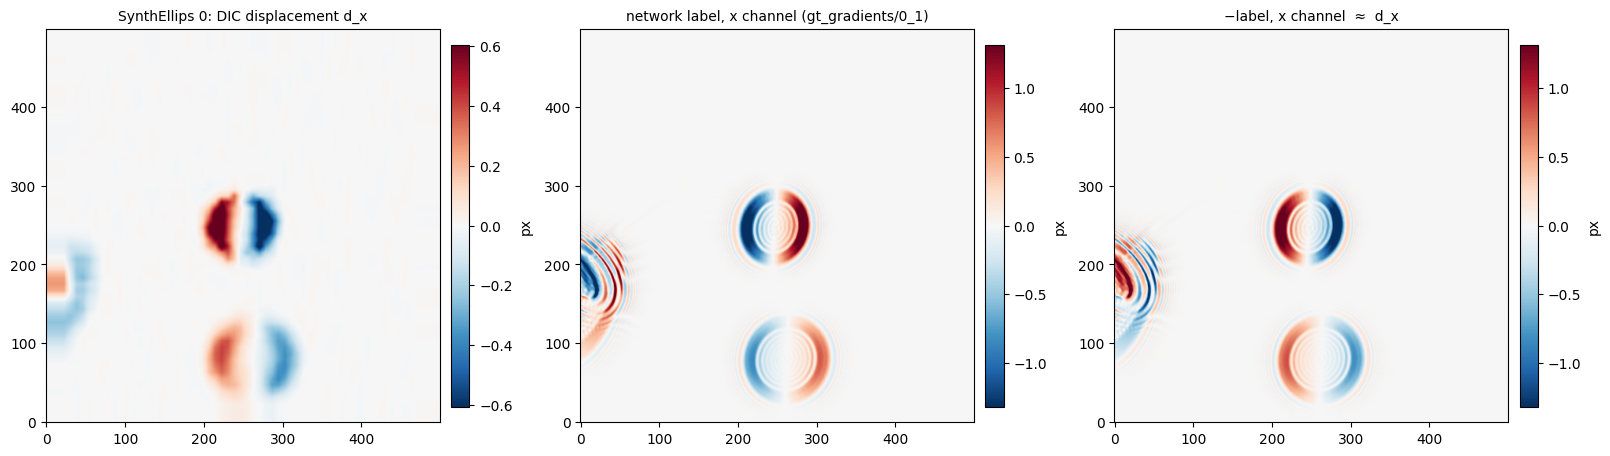

In [5]:
DATA = os.environ.get("SPECKLE_OPD_DATA", os.path.join("..", "..", "data"))
SYN = os.path.join(DATA, "2025-12-03_synthellips_v0_synthetic_cwfs_pairs_with_ground_truth")
if not os.path.isdir(SYN):
    print("SynthEllips data not found; set SPECKLE_OPD_DATA")
else:
    cfg = json.load(open(os.path.join(SYN, "data_creation_cwfs_params.json")))["data_saving_params"]
    rows = []
    for i in range(3):
        I0s, I1s = (load_image(os.path.join(SYN, d, f"{i}.tiff")) for d in ("reference", "specimen"))
        labels = np.stack([load_image(os.path.join(SYN, "gt_gradients", f"{i}_{ch}.tiff")) / cfg["GRAD_DATA_SCALE"]
                           - cfg["GRAD_DATA_BIAS"] for ch in (0, 1)])
        d = get_method("dic", Setup(1, 1), saturation=float(I0s.max())).retrieve(I0s, I1s).displacement
        sl = (slice(40, -40), slice(40, -40))
        rows.append([np.corrcoef(d[ch][sl].ravel(), labels[ch][sl].ravel())[0, 1] for ch in (0, 1)])
        if i == 0:
            d0, l0 = d, labels
    print("corr(DIC d, labels) per pair (y, x):", np.round(rows, 2).tolist())
    fig, axs = plt.subplots(1, 3, figsize=(16, 4.6), layout="constrained")
    show(axs[0], fig, d0[1], "SynthEllips 0: DIC displacement d_x", "px")
    show(axs[1], fig, l0[1], "network label, x channel (gt_gradients/0_1)", "px")
    show(axs[2], fig, -l0[1], "−label, x channel  ≈  d_x", "px")
    plt.show()

## 5. Summary — identical for every method

| Method | What it estimates | Into `core` | OPD |
|---|---|---|---|
| DIC (`dic`) | speckle shift $d$ by ZNCC | $d$ | $+\frac{p^2}{z}\int d$ |
| Deep CWFS (`deep_cwfs`) | network flow ($\approx$ labels $= -d$) | $d = -\text{flow}$ | $+\frac{p^2}{z}\int d$ (= original script) |
| Classical CWFS (to port) | phase-like $\varphi$ | must be converted to $d$ / $\varphi = \int d$ in the package convention | $+\frac{p^2}{z}\varphi$ |

- Higher RI than the medium → **OPD > 0**; lower RI → OPD < 0. `opd_gradient` $= \frac{p}{z}\,d$ has the same sign.
- The sign is applied once, in `core/retriever_interface_and_method_registry.py`; methods only return $d$ (or
  $\varphi = \int d$). There are no per-method sign options.
- Tests that pin the convention: `test_opd_sign_convention_physical_speckle_simulation.py` (physics),
  `test_dic_opd_retriever_end_to_end.py` (DIC), `test_sign_agrees_with_dic` and `test_reproduces_original_inference`
  (Deep CWFS).